# 12G — Locked Forward-Performance Evaluation

This notebook opens outcomes only after text extraction, embedding propagation, portfolio membership, and placebos have been frozen. The primary comparison uses equal-sized, equal-weighted LLM-only and embedding-only portfolios. Embedding performance is also tested against 100 matched-cardinality placebo portfolios.

## 1. Setup and immutable paths

All inputs are local checkpoints. This stage makes no OpenAI API calls and requires no WRDS connection.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().resolve()
if ROOT.name!='sp500_critical_minerals': ROOT=Path('/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals')
CONFIG=ROOT/'config'; PROP=ROOT/'embedding_propagation_v1'; OUT=ROOT/'forward_performance_v1'; OUT.mkdir(exist_ok=True)
RETURNS=ROOT.parent/'quarterly_sec_pilot'/'forward_performance_2025_2026'/'data'/'processed'/'crsp_firm_monthly_through_cutoff.parquet'
UNIVERSE=ROOT/'data'/'processed'/'sp500_point_in_time_membership_with_crsp_ids.parquet'
def sha(p): return hashlib.sha256(p.read_bytes()).hexdigest()
def savej(x,p): p.write_text(json.dumps(x,indent=2,sort_keys=True,default=str)+'\n')
print('Root:',ROOT); print('Return checkpoint:',RETURNS.exists())

Root: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals
Return checkpoint: True


## 2. Verify the frozen design before opening returns

The hashes bind this analysis to the exact portfolios and placebo draws created by 12F. A thematic index is not added after outcome access because that would permit benchmark selection with hindsight.

In [2]:
contract_path=CONFIG/'forward_performance_v1.json'; contract=json.loads(contract_path.read_text())
gates=pd.read_parquet(PROP/'embedding_propagation_gates.parquet'); assert gates.passed.all()
primary_path=PROP/'primary_equal_cardinality_portfolios.parquet'; placebo_path=PROP/'matched_placebo_portfolios_100.parquet'
audit=pd.DataFrame([{'input':x,'path':str(p),'sha256':sha(p)} for x,p in [('contract',contract_path),('primary',primary_path),('placebos',placebo_path),('returns',RETURNS)]])
audit.to_parquet(OUT/'input_hash_audit.parquet',index=False)
display(gates); display(audit[['input','sha256']])

,gate,value,threshold,passed
0,four_vintages,4.000000,4.00,True
1,minimum_embedding_coverage,0.804391,0.75,True
2,equal_primary_cardinality,4.000000,4.00,True
3,zero_seed_candidate_overlap,0.000000,0.00,True
4,one_hundred_placebos_each,100.000000,100.00,True
5,returns_unopened,0.000000,0.00,True


,input,sha256
0,contract,a974564a3f0487847cb80954a7963718d9323aa5823abb...
1,primary,5d4a0cf1fb908a0ac2ffdd0435537fbf5832ca0576861c...
2,placebos,9d414be28bd2cfd95e35f7820a019d5d468f95e4e51864...
3,returns,b8b8c4adc7b6633297fe16c30a7dd0dcd97273734a979c...


## 3. Build the primary three-month outcome

The months were declared in the original design. A firm needs all three monthly observations. Returns are compounded within firm first and then averaged across firms, ensuring each selected firm has one portfolio weight.

In [3]:
design=json.loads((CONFIG/'sp500_experiment_design_v1.json').read_text())
windows=pd.DataFrame([{'vintage':v['label'],'month':pd.Period(m,'M')} for v in design['vintages'] for m in v['forward_months']])
r=pd.read_parquet(RETURNS); r['permco']=pd.to_numeric(r.permco,errors='coerce').astype('Int64'); r['month']=pd.to_datetime(r.eom).dt.to_period('M'); r['eom_ret']=pd.to_numeric(r.eom_ret,errors='coerce')
r=r.dropna(subset=['permco','month','eom_ret']).drop_duplicates(['permco','month'])
u=pd.read_parquet(UNIVERSE); u['permco']=pd.to_numeric(u.permco,errors='coerce').astype('Int64'); u=u[['vintage','permco']].dropna().drop_duplicates()
fw=u.merge(windows,on='vintage',how='inner').merge(r[['permco','month','eom_ret']],on=['permco','month'],how='left',validate='many_to_one')
fb=(fw.groupby(['vintage','permco'],as_index=False).agg(months=('eom_ret','count'),buy_hold_return=('eom_ret',lambda x:np.prod(1+x.dropna())-1 if x.notna().any() else np.nan)))
fb['complete']=fb.months.eq(3)
benchmark=(fb[fb.complete].groupby('vintage',as_index=False).agg(sp500_equal_weight_return=('buy_hold_return','mean'),benchmark_firms=('permco','nunique')))
universe_coverage=(fb.groupby('vintage',as_index=False).agg(universe_firms=('permco','nunique'),complete_return_firms=('complete','sum'))); universe_coverage['coverage']=universe_coverage.complete_return_firms/universe_coverage.universe_firms
display(universe_coverage.merge(benchmark,on='vintage'))

,vintage,universe_firms,complete_return_firms,coverage,sp500_equal_weight_return,benchmark_firms
0,2024q1,500,467,0.934,0.06171,467
1,2024q2,500,468,0.936,0.072802,468
2,2024q3,501,410,0.818363,-0.041376,410
3,2024q4,500,412,0.824,0.055236,412


## 4. Primary LLM-versus-embedding comparison

The portfolios have equal cardinality within vintage and are disjoint. The matched absolute-return difference is primary. The available-universe average is shown only as a descriptive common-support diagnostic because the local checkpoint does not cover every S&P 500 firm.

In [4]:
p=pd.read_parquet(primary_path); p['permco']=pd.to_numeric(p.permco,errors='coerce').astype('Int64'); pp=p.merge(fb,on=['vintage','permco'],how='left',validate='many_to_one')
def summarize(g):
    z=g[g.complete]
    return pd.Series({'selected_firms':g.permco.nunique(),'observed_firms':z.permco.nunique(),'portfolio_return':z.buy_hold_return.mean()})
primary=pp.groupby(['vintage','portfolio'],as_index=False).apply(summarize,include_groups=False).reset_index(drop=True)
primary=primary.merge(benchmark,on='vintage',validate='many_to_one').rename(columns={'sp500_equal_weight_return':'available_universe_return'}); primary['available_universe_adjusted_return']=primary.portfolio_return-primary.available_universe_return
w=primary.pivot(index='vintage',columns='portfolio',values='portfolio_return').reset_index(); w['embedding_minus_llm']=w.embedding_only_primary-w.llm_only_common_support
primary.to_parquet(OUT/'primary_portfolio_results.parquet',index=False); w.to_parquet(OUT/'primary_paired_comparison.parquet',index=False)
display(primary); display(w)

,vintage,portfolio,selected_firms,observed_firms,portfolio_return,available_universe_return,benchmark_firms,available_universe_adjusted_return
0,2024q1,embedding_only_primary,14.0,14.0,-0.057448,0.06171,467,-0.119157
1,2024q1,llm_only_common_support,14.0,14.0,-0.012339,0.06171,467,-0.074049
2,2024q2,embedding_only_primary,13.0,13.0,0.030087,0.072802,468,-0.042715
3,2024q2,llm_only_common_support,13.0,13.0,0.031555,0.072802,468,-0.041247
4,2024q3,embedding_only_primary,15.0,15.0,-0.017870,-0.041376,410,0.023506
5,2024q3,llm_only_common_support,15.0,15.0,-0.137245,-0.041376,410,-0.095869
6,2024q4,embedding_only_primary,15.0,15.0,0.030347,0.055236,412,-0.024888
7,2024q4,llm_only_common_support,15.0,15.0,0.092421,0.055236,412,0.037185


portfolio,vintage,embedding_only_primary,llm_only_common_support,embedding_minus_llm
0,2024q1,-0.057448,-0.012339,-0.045108
1,2024q2,0.030087,0.031555,-0.001468
2,2024q3,-0.017870,-0.137245,0.119375
3,2024q4,0.030347,0.092421,-0.062073


## 5. Matched-placebo inference

Every placebo has the same cardinality as the embedding-only portfolio in its vintage. The pooled test preserves placebo draw identity across quarters and compares four-vintage mean returns.

In [5]:
pl=pd.read_parquet(placebo_path); pl['permco']=pd.to_numeric(pl.permco,errors='coerce').astype('Int64'); xp=pl.merge(fb,on=['vintage','permco'],how='left',validate='many_to_one')
placebo=xp.groupby(['vintage','placebo_draw'],as_index=False).apply(summarize,include_groups=False).reset_index(drop=True).rename(columns={'portfolio_return':'placebo_return'})
obs=primary[primary.portfolio.eq('embedding_only_primary')][['vintage','portfolio_return']].rename(columns={'portfolio_return':'embedding_return'})
placebo=placebo.merge(obs,on='vintage',validate='many_to_one')
def ps(g):
    o=g.embedding_return.iloc[0]; x=g.placebo_return.dropna(); return pd.Series({'embedding_return':o,'placebo_mean':x.mean(),'placebo_q05':x.quantile(.05),'placebo_q50':x.quantile(.5),'placebo_q95':x.quantile(.95),'embedding_percentile':(x<o).mean(),'one_sided_empirical_p':(1+(x>=o).sum())/(1+len(x)),'draws':len(x)})
by_vintage=placebo.groupby('vintage',as_index=False).apply(ps,include_groups=False).reset_index(drop=True)
pooled=placebo.groupby('placebo_draw',as_index=False).placebo_return.mean().rename(columns={'placebo_return':'mean_placebo_return'}); om=obs.embedding_return.mean(); x=pooled.mean_placebo_return
pooled_summary=pd.DataFrame([{'vintages':4,'embedding_mean_return':om,'placebo_mean_return':x.mean(),'placebo_q05':x.quantile(.05),'placebo_q95':x.quantile(.95),'embedding_percentile':(x<om).mean(),'one_sided_empirical_p':(1+(x>=om).sum())/(1+len(x))}])
placebo.to_parquet(OUT/'matched_placebo_returns.parquet',index=False); by_vintage.to_parquet(OUT/'matched_placebo_summary.parquet',index=False); pooled.to_parquet(OUT/'pooled_placebo_distribution.parquet',index=False); pooled_summary.to_parquet(OUT/'pooled_placebo_summary.parquet',index=False)
display(by_vintage); display(pooled_summary)

,vintage,embedding_return,placebo_mean,placebo_q05,placebo_q50,placebo_q95,embedding_percentile,one_sided_empirical_p,draws
0,2024q1,-0.057448,0.070351,0.026945,0.073052,0.119525,0.00,1.000000,100.0
1,2024q2,0.030087,0.079407,0.018228,0.082663,0.137339,0.12,0.881188,100.0
2,2024q3,-0.017870,-0.030370,-0.084712,-0.025630,0.009109,0.66,0.346535,100.0
3,2024q4,0.030347,0.038806,-0.021193,0.028872,0.126802,0.51,0.495050,100.0


,vintages,embedding_mean_return,placebo_mean_return,placebo_q05,placebo_q95,embedding_percentile,one_sided_empirical_p
0,4,-0.003721,0.039548,0.0115,0.068083,0.0,1.0


## 6. Coverage, gates, and visualization

The chart is descriptive; matched-placebo inference is the formal test. All portfolio and benchmark coverage gates must pass.

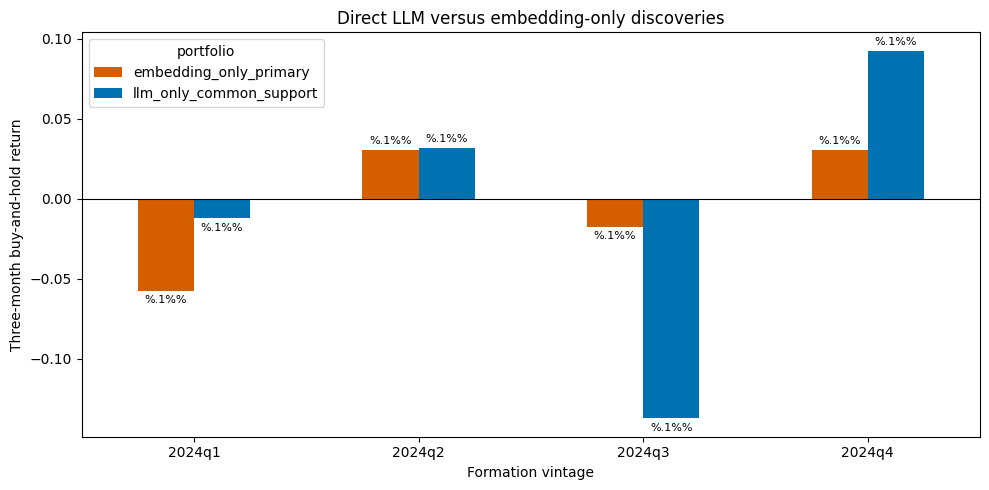

,vintage,portfolio,selected_firms,observed_firms,return_coverage
0,2024q1,embedding_only_primary,14.0,14.0,1.0
1,2024q1,llm_only_common_support,14.0,14.0,1.0
2,2024q2,embedding_only_primary,13.0,13.0,1.0
3,2024q2,llm_only_common_support,13.0,13.0,1.0
4,2024q3,embedding_only_primary,15.0,15.0,1.0
5,2024q3,llm_only_common_support,15.0,15.0,1.0
6,2024q4,embedding_only_primary,15.0,15.0,1.0
7,2024q4,llm_only_common_support,15.0,15.0,1.0


,gate,value,threshold,passed
0,four_vintages,4.000000,4.0,True
1,equal_primary_cardinality,4.000000,4.0,True
2,minimum_primary_return_coverage,1.000000,0.9,True
3,minimum_descriptive_universe_coverage,0.818363,0.8,True
4,one_hundred_placebos_each,100.000000,100.0,True


In [6]:
diag=primary[['vintage','portfolio','selected_firms','observed_firms']].copy(); diag['return_coverage']=diag.observed_firms/diag.selected_firms
card=primary.pivot(index='vintage',columns='portfolio',values='selected_firms')
fg=pd.DataFrame([
 {'gate':'four_vintages','value':primary.vintage.nunique(),'threshold':4,'passed':primary.vintage.nunique()==4},
 {'gate':'equal_primary_cardinality','value':int((card.embedding_only_primary==card.llm_only_common_support).sum()),'threshold':4,'passed':bool((card.embedding_only_primary==card.llm_only_common_support).all())},
 {'gate':'minimum_primary_return_coverage','value':diag.return_coverage.min(),'threshold':.90,'passed':diag.return_coverage.min()>=.90},
 {'gate':'minimum_descriptive_universe_coverage','value':universe_coverage.coverage.min(),'threshold':.80,'passed':universe_coverage.coverage.min()>=.80},
 {'gate':'one_hundred_placebos_each','value':placebo.groupby('vintage').placebo_draw.nunique().min(),'threshold':100,'passed':placebo.groupby('vintage').placebo_draw.nunique().min()==100}])
diag.to_parquet(OUT/'return_coverage_diagnostics.parquet',index=False); fg.to_parquet(OUT/'forward_performance_gates.parquet',index=False)
plot=primary.pivot(index='vintage',columns='portfolio',values='portfolio_return'); ax=plot.plot.bar(figsize=(10,5),color=['#D55E00','#0072B2']); ax.axhline(0,color='black',lw=.8); ax.set_ylabel('Three-month buy-and-hold return'); ax.set_xlabel('Formation vintage'); ax.set_title('Direct LLM versus embedding-only discoveries')
for q in ax.containers: ax.bar_label(q,fmt='%.1%%',padding=3,fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(OUT/'primary_portfolio_returns.png',dpi=180,bbox_inches='tight'); plt.show()
display(diag); display(fg); assert fg.passed.all()

## 7. Reproducibility manifest and interpretation boundary

With four vintages, this is a disciplined proof-of-concept rather than definitive time-series evidence. No factor alpha is claimed from three observations per vintage, and the cached return checkpoint does not expose a separate delisting-return field.

In [7]:
arts=[]
for f in sorted(OUT.glob('*')):
    if f.is_file() and f.name!='forward_performance_manifest.json': arts.append({'artifact':f.name,'rows':len(pd.read_parquet(f)) if f.suffix=='.parquet' else None,'bytes':f.stat().st_size,'sha256':sha(f)})
manifest={'stage':'locked_forward_performance_v1','contract_sha256':sha(contract_path),'all_gates_passed':bool(fg.passed.all()),'vintages':sorted(primary.vintage.unique()),'limitations':['four vintages','three-month primary horizon','no separate delisting-return field','no pre-frozen thematic index'],'artifacts':arts}
savej(manifest,OUT/'forward_performance_manifest.json'); display(pd.DataFrame(arts)); print('Saved:',OUT)

,artifact,rows,bytes,sha256
0,forward_performance_gates.parquet,5.0,2893,9b4e36dfb54203a51efa0f347c54ed4eaf0d965a30d390...
1,input_hash_audit.parquet,4.0,3645,5e8a384693fbcad8634fae0e2a55c94d057c7723c293a6...
2,matched_placebo_returns.parquet,400.0,8651,881212bafa921e74a50066523e4230ccf0b01330c70552...
3,matched_placebo_summary.parquet,4.0,6151,2ab30f59789c51b6113c9b355e58460619aac89e1369be...
4,pooled_placebo_distribution.parquet,100.0,3271,d076db139746a521d2557cfedfce917a6292cc565144de...
5,pooled_placebo_summary.parquet,1.0,4990,f903a3c725ce146d2925f81b80f0488af125c5042f9747...
6,primary_paired_comparison.parquet,4.0,3223,9eebfafb29a5a43aa1a6fcc3ca1a342cad3ca20b1ee0aa...
7,primary_portfolio_results.parquet,8.0,5904,81cde1d1cf920dab117fb20fc481b75bf9876237766af4...
8,primary_portfolio_returns.png,NaN,64929,65bddd7d7b51e5ec2e817a4152d5ae2d855d8630cc062f...
9,return_coverage_diagnostics.parquet,8.0,3640,0e8eaffd2e311a18bc6f224ec09caedaa50ab8670e3c05...


Saved: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals/forward_performance_v1
